# Análise Exploratória de Dados (EDA)

Este notebook apresenta a análise exploratória do dataset de previsão de burnout, incluindo caracterização dos dados, estatísticas descritivas, valores ausentes, outliers, correlações e visualizações.

## Carregamento do dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../datasets/mental_health_burnout_prediction_dataset.csv"
)

df.head()

,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,1,58.0,Male,United States,Marketing Manager,Diploma,Employed,2786.0,67,Hybrid,...,No,Yes,Average,6.0,19.0,2,82,Critical,Practice Mindfulness,High
1,2,24.0,Female,Pakistan,Freelancer,Bachelor,Student,8027.0,44,Hybrid,...,Yes,No,Good,4.0,27.0,22,64,Critical,Reduce Workload,Moderate
2,3,59.0,Male,Malaysia,Accountant,PhD,Employed,3177.0,60,No,...,Yes,No,Average,4.0,51.0,17,50,Needs Attention,Increase Physical Activity,Moderate
3,4,65.0,Other,Mexico,Chef,Master,Self-Employed,4093.0,25,Yes,...,No,Yes,Good,7.0,83.0,14,16,Healthy,Maintain Healthy Routine,Low
4,5,64.0,Other,Japan,Farmer,Diploma,Student,NaN,52,No,...,Yes,No,Poor,9.0,61.0,4,26,Healthy,Reduce Workload,Low


# Mostrar as últimas linhas

In [2]:
df.tail()

,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
49995,49996,36.0,Male,Australia,Teacher,High School,Self-Employed,3540.0,43,Yes,...,Yes,No,Average,3.0,47.0,27,61,Needs Attention,Increase Physical Activity,Moderate
49996,49997,57.0,Female,Turkey,Freelancer,PhD,Student,10630.0,24,No,...,No,Yes,Excellent,4.0,87.0,4,0,Healthy,Improve Sleep,Low
49997,49998,34.0,Male,South Africa,Student,Diploma,Student,3143.0,56,Hybrid,...,No,Yes,Poor,4.0,42.0,7,75,Critical,Take Regular Breaks,High
49998,49999,61.0,Other,Singapore,Business Owner,Bachelor,Employed,3781.0,29,No,...,No,Yes,Poor,8.0,75.0,0,24,Healthy,Improve Sleep,Low
49999,50000,49.0,Male,South Africa,Doctor,Master,Unemployed,8864.0,68,Hybrid,...,No,No,Good,6.0,11.0,8,69,Critical,Practice Mindfulness,High


# Ver o tamanho do dataset

In [3]:
print("Linhas:", df.shape[0])
print("Colunas:", df.shape[1])

Linhas: 50000
Colunas: 40


# Ver os tipos das colunas

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 40 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Person_ID                      50000 non-null  int64  
 1   Age                            49750 non-null  float64
 2   Gender                         50000 non-null  object 
 3   Country                        50000 non-null  object 
 4   Occupation                     50000 non-null  object 
 5   Education_Level                50000 non-null  object 
 6   Employment_Status              50000 non-null  object 
 7   Monthly_Income_USD             48550 non-null  float64
 8   Work_Hours_Per_Week            50000 non-null  int64  
 9   Remote_Work                    50000 non-null  object 
 10  Job_Satisfaction               49500 non-null  float64
 11  Work_Life_Balance              49350 non-null  float64
 12  Sleep_Hours                    49050 non-null 

# Estatísticas descritivas

Variáveis numéricas:

In [7]:
df.describe()

,Person_ID,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,...,Physical_Activity_Hours,Meditation_Minutes,Screen_Time_Hours,Social_Media_Hours,Gaming_Hours,Coffee_Cups_Per_Day,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score
count,50000.000000,49750.000000,48550.000000,50000.000000,49500.000000,49350.000000,49050.000000,49200.000000,49150.000000,49100.000000,...,48900.000000,48800.000000,49150.000000,49400.000000,49250.000000,50000.000000,49300.000000,49050.000000,50000.000000,50000.00000
mean,25000.500000,41.448181,6251.281524,44.946160,5.499051,5.504397,6.997445,40.449045,40.601160,59.622994,...,4.988035,30.028955,7.991274,3.991674,2.988227,3.991440,5.521298,59.444179,14.970220,40.20188
std,14433.901067,13.871634,3319.661435,14.729024,2.866621,2.867492,1.728766,26.004291,26.308933,25.783486,...,2.870014,17.607139,3.472498,2.305422,1.728545,2.581221,2.868514,26.028764,8.965856,26.22312
min,1.000000,18.000000,500.000000,20.000000,1.000000,1.000000,4.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000
25%,12500.750000,29.000000,3381.000000,32.000000,3.000000,3.000000,5.500000,19.000000,19.000000,41.000000,...,2.500000,15.000000,5.000000,2.000000,1.500000,2.000000,3.000000,41.000000,7.000000,19.00000
50%,25000.500000,41.000000,6231.000000,45.000000,6.000000,6.000000,7.000000,39.000000,39.000000,61.000000,...,5.000000,30.000000,8.000000,4.000000,3.000000,4.000000,6.000000,61.000000,15.000000,39.00000
75%,37500.250000,53.000000,9134.000000,58.000000,8.000000,8.000000,8.500000,59.000000,60.000000,80.000000,...,7.400000,45.000000,11.000000,6.000000,4.500000,6.000000,8.000000,81.000000,23.000000,59.00000
max,50000.000000,65.000000,12000.000000,70.000000,10.000000,10.000000,10.000000,100.000000,100.000000,100.000000,...,10.000000,60.000000,14.000000,8.000000,6.000000,8.000000,10.000000,100.000000,30.000000,100.00000


Mediana:

In [8]:
df.median(numeric_only=True)

Person_ID                  25000.5
Age                           41.0
Monthly_Income_USD          6231.0
Work_Hours_Per_Week           45.0
Job_Satisfaction               6.0
Work_Life_Balance              6.0
Sleep_Hours                    7.0
Anxiety_Score                 39.0
Depression_Score              39.0
Mood_Score                    61.0
Emotional_Stability           60.0
Physical_Activity_Hours        5.0
Meditation_Minutes            30.0
Screen_Time_Hours              8.0
Social_Media_Hours             4.0
Gaming_Hours                   3.0
Coffee_Cups_Per_Day            4.0
Life_Satisfaction              6.0
Productivity_Score            61.0
Absenteeism_Days              15.0
Burnout_Score                 39.0
dtype: float64

# Frequência das variáveis categóricas

In [4]:
colunas_categoricas = df.select_dtypes(
    include="object"
).columns

for coluna in colunas_categoricas:
    print("\n", coluna)
    print(df[coluna].value_counts())


 Gender
Gender
Female    16810
Male      16681
Other     16509
Name: count, dtype: int64

 Country
Country
South Africa            2098
Canada                  2061
Russia                  2051
Saudi Arabia            2043
Pakistan                2039
Spain                   2031
Turkey                  2030
South Korea             2029
France                  2021
United States           2014
Mexico                  2010
Germany                 2003
Egypt                   2003
Japan                   1999
Singapore               1989
India                   1985
Australia               1985
United Kingdom          1983
Indonesia               1975
Malaysia                1974
United Arab Emirates    1960
China                   1951
Nigeria                 1946
Brazil                  1915
Italy                   1905
Name: count, dtype: int64

 Occupation
Occupation
Student              2603
Doctor               2590
Marketing Manager    2552
Nurse                2536
Researcher   

# Verificar valores ausentes

In [11]:
df.isnull().sum()

Person_ID                           0
Age                               250
Gender                              0
Country                             0
Occupation                          0
Education_Level                     0
Employment_Status                   0
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Remote_Work                         0
Job_Satisfaction                  500
Work_Life_Balance                 650
Sleep_Hours                       950
Sleep_Quality                       0
Stress_Level                        0
Anxiety_Score                     800
Depression_Score                  850
Mood_Score                        900
Emotional_Stability                 0
Physical_Activity_Hours          1100
Exercise_Frequency                  0
Meditation_Minutes               1200
Screen_Time_Hours                 850
Social_Media_Hours                600
Gaming_Hours                      750
Coffee_Cups_Per_Day                 0
Alcohol_Cons

Cálculo do Percentual:

In [12]:
faltantes = pd.DataFrame({
    "Quantidade": df.isnull().sum(),
    "Percentual": df.isnull().mean() * 100
})

faltantes = faltantes[
    faltantes["Quantidade"] > 0
].sort_values(
    "Quantidade",
    ascending=False
)

faltantes

,Quantidade,Percentual
Monthly_Income_USD,1450,2.9
Meditation_Minutes,1200,2.4
Physical_Activity_Hours,1100,2.2
Sleep_Hours,950,1.9
Productivity_Score,950,1.9
Mood_Score,900,1.8
Screen_Time_Hours,850,1.7
Depression_Score,850,1.7
Anxiety_Score,800,1.6
Gaming_Hours,750,1.5


# Criar gráfico de valores ausentes

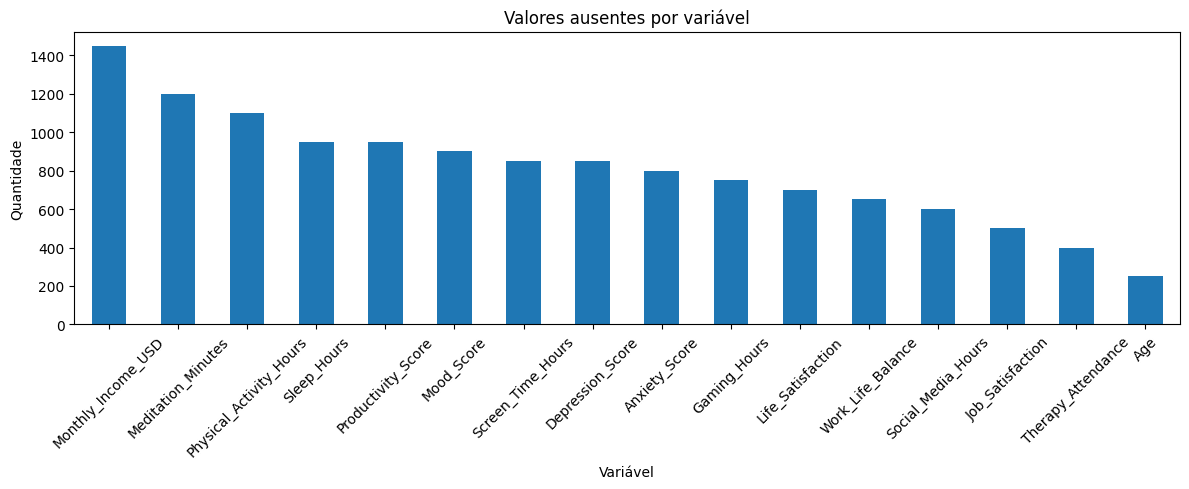

In [13]:
faltantes["Quantidade"].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Valores ausentes por variável")
plt.ylabel("Quantidade")
plt.xlabel("Variável")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../reports/figures/missing_values.png",
    dpi=300
)

plt.show()

# Analisar outliers

In [14]:
numericas = df.select_dtypes(
    include=np.number
).columns

for coluna in numericas:
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ]

    print(coluna, ":", len(outliers))

Person_ID : 0
Age : 0
Monthly_Income_USD : 0
Work_Hours_Per_Week : 0
Job_Satisfaction : 0
Work_Life_Balance : 0
Sleep_Hours : 0
Anxiety_Score : 0
Depression_Score : 0
Mood_Score : 0
Emotional_Stability : 0
Physical_Activity_Hours : 0
Meditation_Minutes : 0
Screen_Time_Hours : 0
Social_Media_Hours : 0
Gaming_Hours : 0
Coffee_Cups_Per_Day : 0
Life_Satisfaction : 0
Productivity_Score : 0
Absenteeism_Days : 0
Burnout_Score : 0


# Visualização dos Outliers com Boxplots

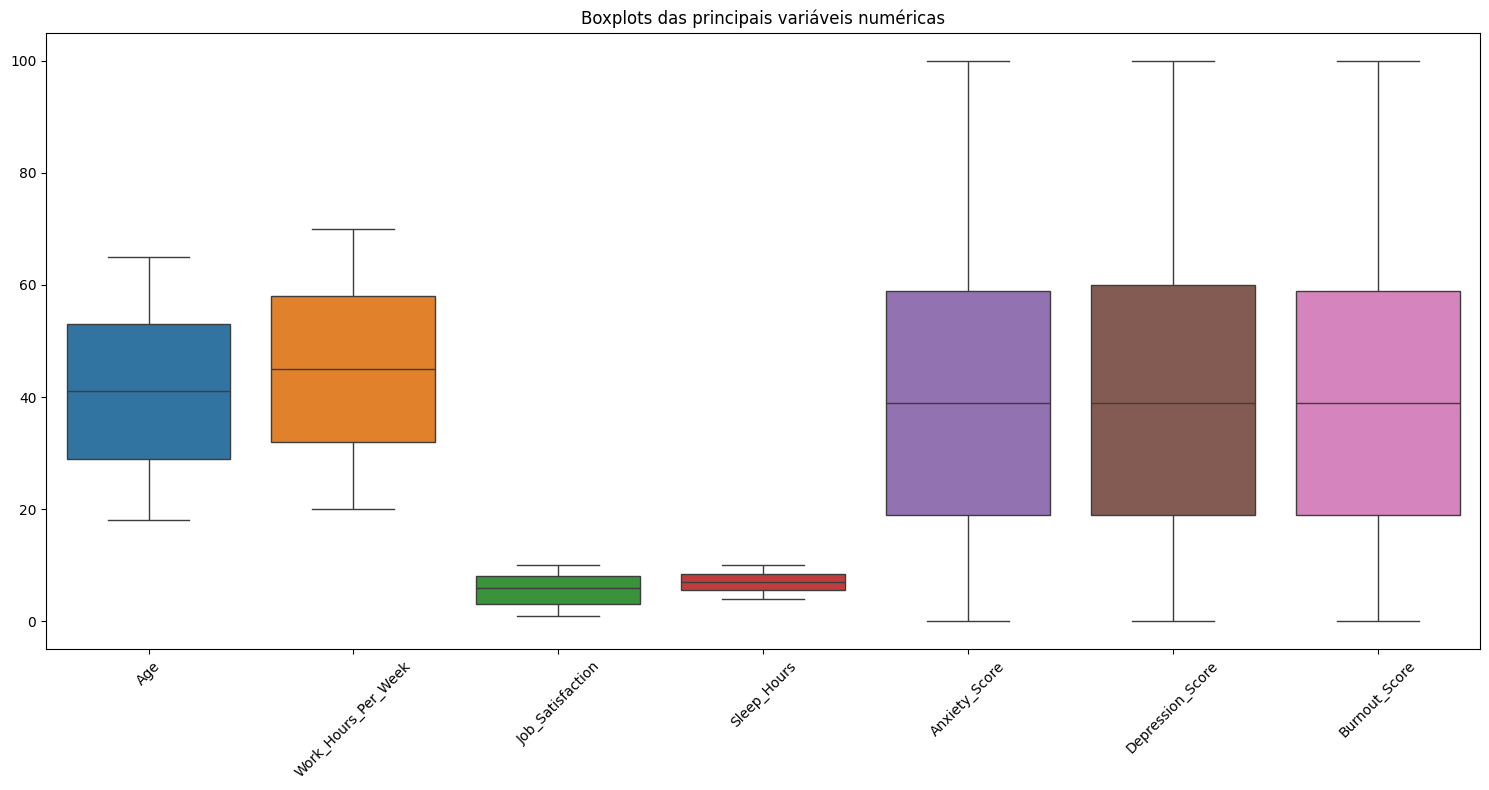

In [15]:
plt.figure(figsize=(15, 8))

sns.boxplot(
    data=df[
        [
            "Age",
            "Work_Hours_Per_Week",
            "Job_Satisfaction",
            "Sleep_Hours",
            "Anxiety_Score",
            "Depression_Score",
            "Burnout_Score"
        ]
    ]
)

plt.xticks(rotation=45)
plt.title("Boxplots das principais variáveis numéricas")
plt.tight_layout()

plt.savefig(
    "../reports/figures/outliers_boxplot.png",
    dpi=300
)

plt.show()

# Fazer matriz de correlação

In [16]:
correlacao = df.select_dtypes(
    include=np.number
).corr()

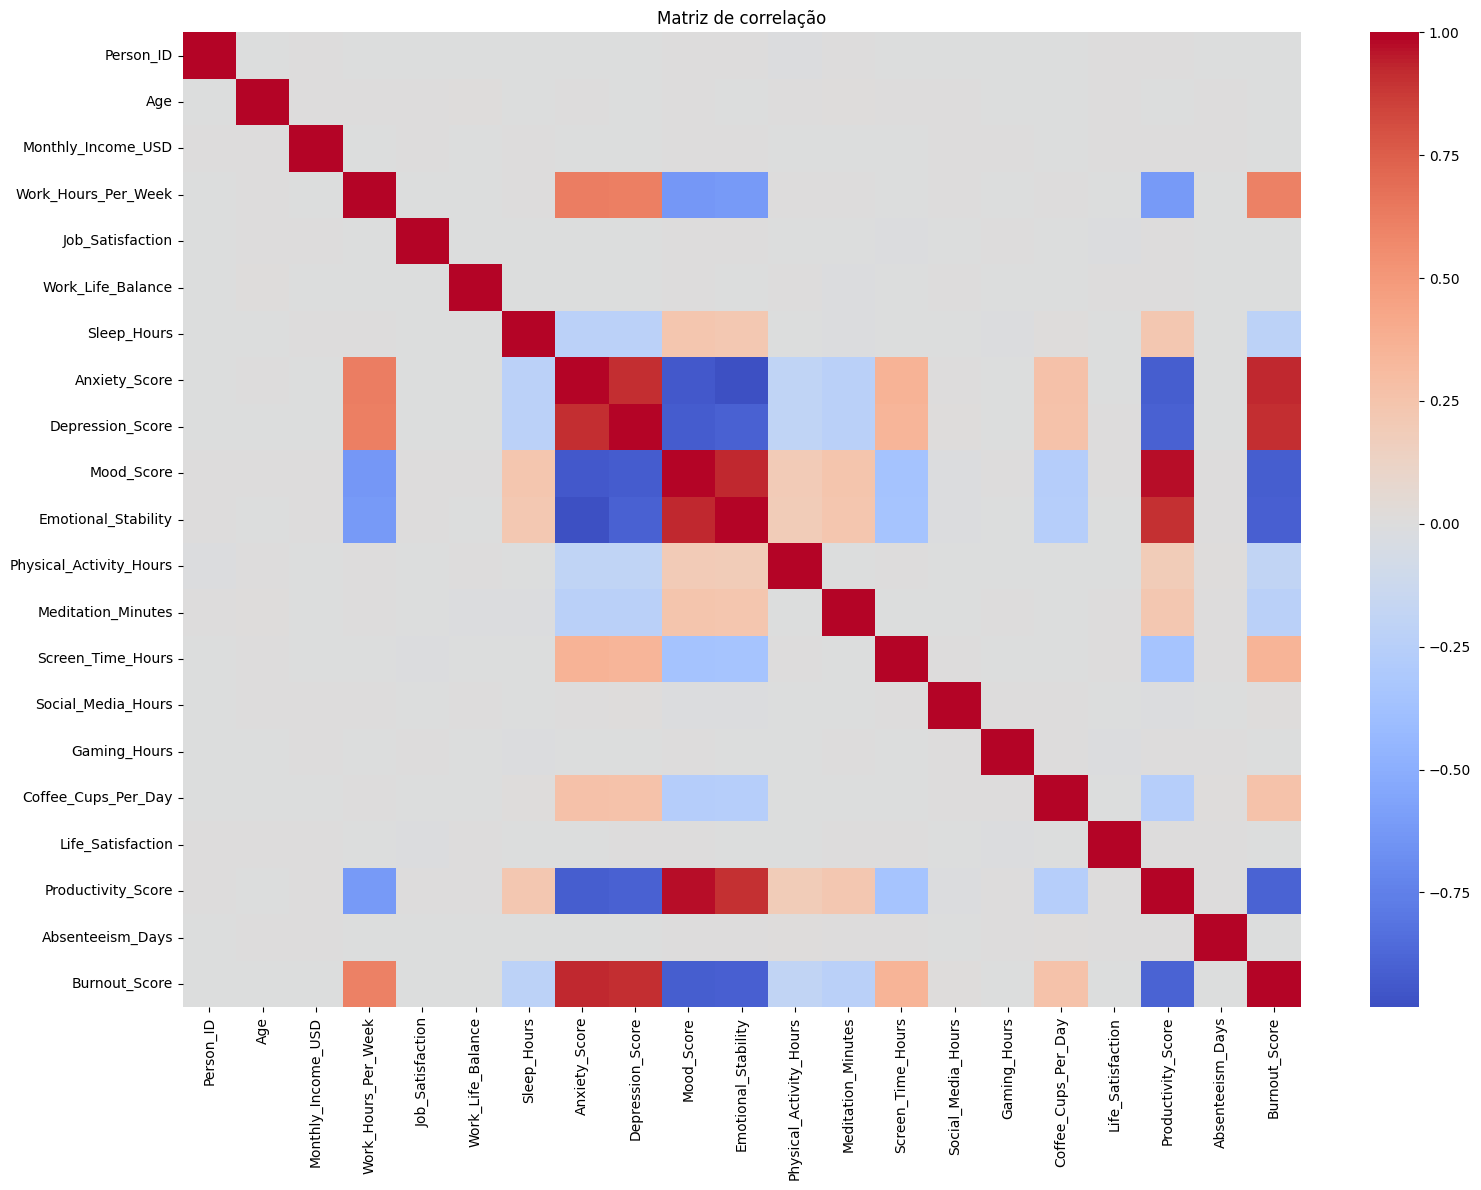

In [17]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlacao,
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlação")
plt.tight_layout()

plt.savefig(
    "../reports/figures/correlation_matrix.png",
    dpi=300
)

plt.show()

# Descobrir as correlações com Burnout_Score

In [18]:
correlacao_burnout = (
    correlacao["Burnout_Score"]
    .sort_values(ascending=False)
)

print(correlacao_burnout)

Burnout_Score              1.000000
Anxiety_Score              0.924406
Depression_Score           0.910755
Work_Hours_Per_Week        0.607838
Screen_Time_Hours          0.349397
Coffee_Cups_Per_Day        0.263934
Social_Media_Hours         0.008647
Age                        0.000212
Work_Life_Balance          0.000179
Monthly_Income_USD        -0.001365
Life_Satisfaction         -0.001383
Job_Satisfaction          -0.001729
Gaming_Hours              -0.002213
Absenteeism_Days          -0.003969
Person_ID                 -0.005055
Physical_Activity_Hours   -0.189655
Sleep_Hours               -0.221917
Meditation_Minutes        -0.233005
Productivity_Score        -0.893543
Emotional_Stability       -0.909691
Mood_Score                -0.917170
Name: Burnout_Score, dtype: float64


# Distribuição do Burnout Score

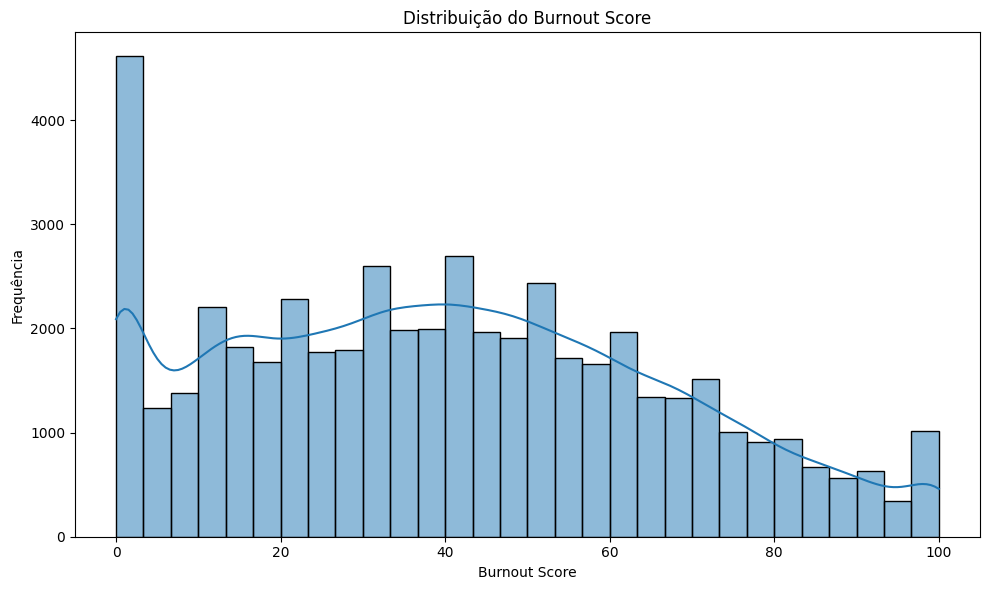

In [5]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Burnout_Score",
    bins=30,
    kde=True
)

plt.title("Distribuição do Burnout Score")
plt.xlabel("Burnout Score")
plt.ylabel("Frequência")

plt.tight_layout()

plt.savefig(
    "../reports/figures/burnout_score_distribution.png",
    dpi=300
)

plt.show()

# Relação entre Horas de Trabalho e Burnout Score

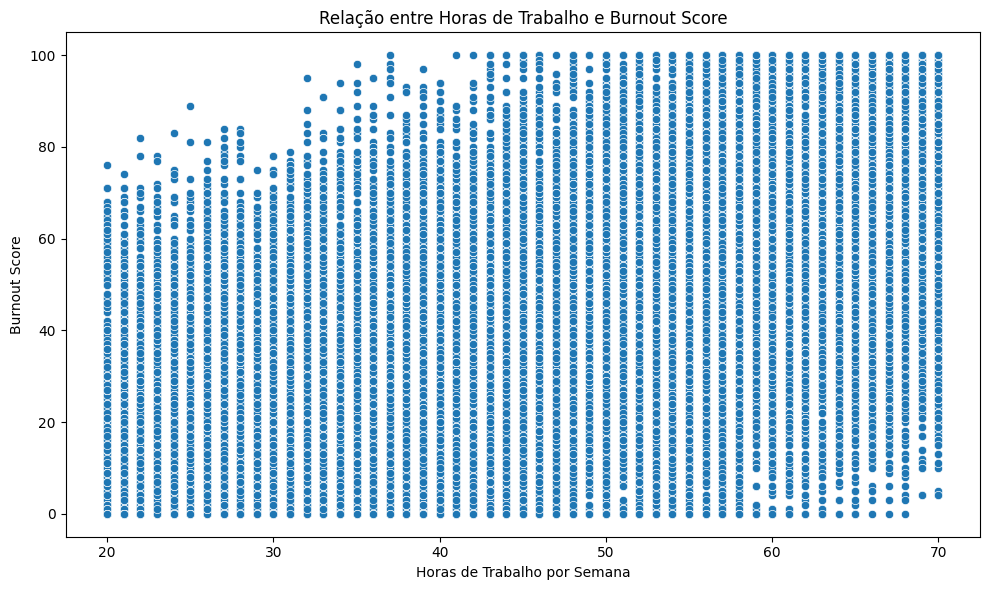

In [6]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Work_Hours_Per_Week",
    y="Burnout_Score"
)

plt.title(
    "Relação entre Horas de Trabalho e Burnout Score"
)

plt.xlabel("Horas de Trabalho por Semana")
plt.ylabel("Burnout Score")

plt.tight_layout()

plt.savefig(
    "../reports/figures/burnout_vs_work_hours.png",
    dpi=300
)

plt.show()